## A1 Outlier detection

The purpose of this assignment is to investigate outlier detection on a multidimensional dataset. I choose to use one of the recommended datasets, specifically the AI4I Predictive Maintenance dataset.

The main objective is not only to identify observations that are considered unusual, but also to investigate why they are unusual and how the results depend on the selected outlier detection method and its parameters.

The analysis consists of:

1. Exploring and preprocessing the dataset
2. Applying Local Outlier Factor (LOF) with different neighbourhood sizes.
3. Investigating the observations receiving the highest LOF scores.
4. Comparing LOF with Isolation Forest and a k-nearest-neighboor distance method.
5. Investigating the influence of important algorithm parameters.
6. Comparing and interpreting the results of the three methods.

### Libraries

In [106]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA

from scipy.stats import spearmanr

pd.set_option("display.max_columns", None)

The analysis uses pandas and NumPy for data handling, Matplotlib for visualization, and implementations from scikit-learn for preprocessing and outlier detection. The outlier detection algorithms are not implemented from scratch because we were allowed to use existing implementations. PCA is used only for visualizing the multidimensional observations in two dimensions. Outlier detection itself is performed using the selected original features.

### Load the dataset

In [107]:
df = pd.read_csv("ai4i2020.csv")

df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [108]:
print("Number of observations:", df.shape[0])
print("Number of features:", df.shape[1])

df.info()

Number of observations: 10000
Number of features: 14
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                     

The dataset contians 10 000 observations and 14 columns. Each observation represents one machine instance/operating observation and contains information about its operating conditions togheter with indicators of machine failure. The dataset contains both numerical and categorical variables. Some columns, such as UDI and Product ID, are identifiers rather than measurements of machine operation. The Type variable is categorical, while the temperature, rotational-speed, torque, and tool-wear variables are numerical measurements. The Machine failure variable and the individual failure-type variables are binary indicators decribing observed failures.

In [109]:
df.columns.tolist()

['UDI',
 'Product ID',
 'Type',
 'Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]',
 'Machine failure',
 'TWF',
 'HDF',
 'PWF',
 'OSF',
 'RNF']

### Dataset attributes

The dataset contains the following groups of attributes:

**Identifiers**
- UDI - unique identifier for an observation
- Product ID - unique product identifier

**Product information**
- Type - product quality/type category

**Machine operating measurements**
- Air temperature [K]
- Process temperature [K]
- Rotational speed [rpm]
- Torque [Nm]
- Tool wear [min]

**Failure information**
- Machine failure - indicates whether a machine failure occurred
- TWF - Tool Wear Failure
- HDF - Heat Dissipation Failure
- PWF - Power Failure
- OSF - Overstrain Failure
- RNF - Random Failure



## Dataquality investigaion

### Missing values

In [110]:
pd.DataFrame({
    "Missing values": df.isnull().sum(),
    "Percentage": df.isnull().mean() * 100
})

,Missing values,Percentage
UDI,0,0.0
Product ID,0,0.0
Type,0,0.0
Air temperature [K],0,0.0
Process temperature [K],0,0.0
Rotational speed [rpm],0,0.0
Torque [Nm],0,0.0
Tool wear [min],0,0.0
Machine failure,0,0.0
TWF,0,0.0


No missing values are present in the dataset. Therefore, no imputation or removal of observations is necessary because of missing data.

### Duplicates

In [111]:
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


No exact diplicate rows were found. Therefore, no observations are removed as duplicates. Duplicate observations could affect neighbourhood-based methods such as LOF because repeated observations alter the local density of the dataset. Since no duplicates are present, no correction is required.

### Descriptive statistics

In [112]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


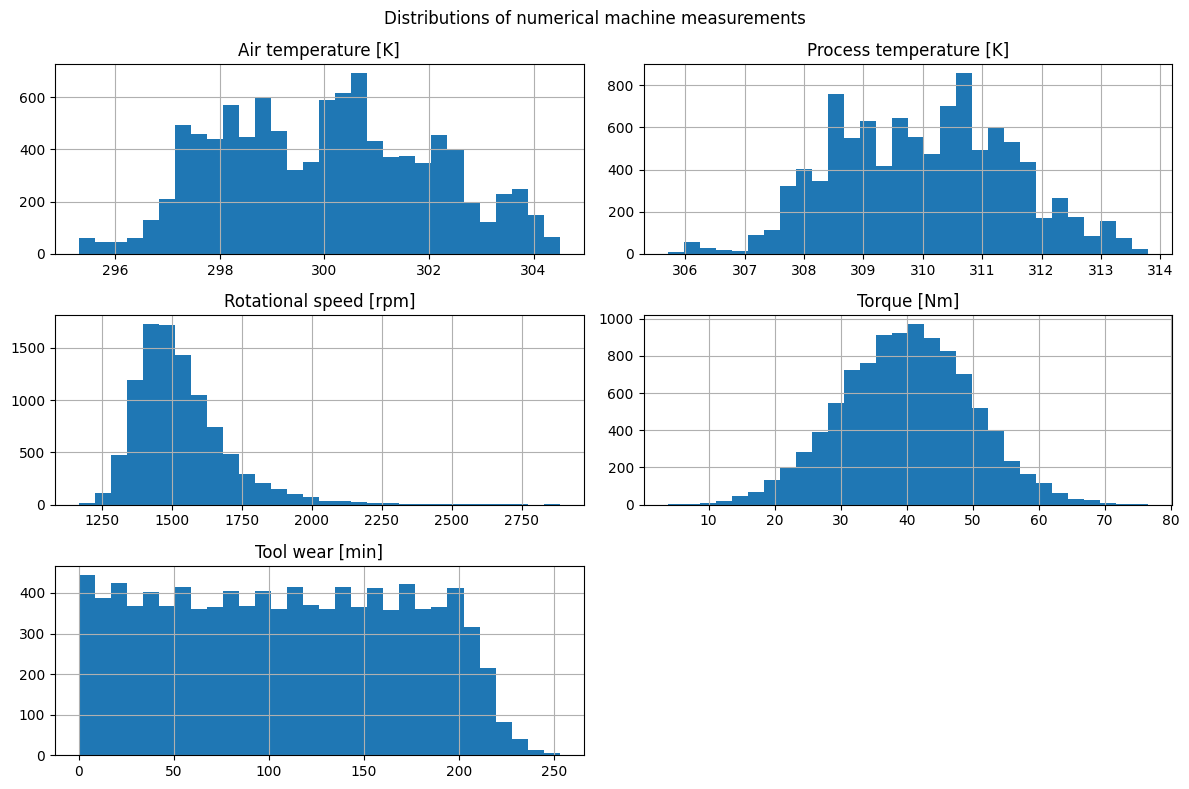

In [113]:
measurement_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[measurement_features].hist(
    figsize=(12, 8),
    bins=30
)

plt.suptitle("Distributions of numerical machine measurements")
plt.tight_layout()
plt.show()

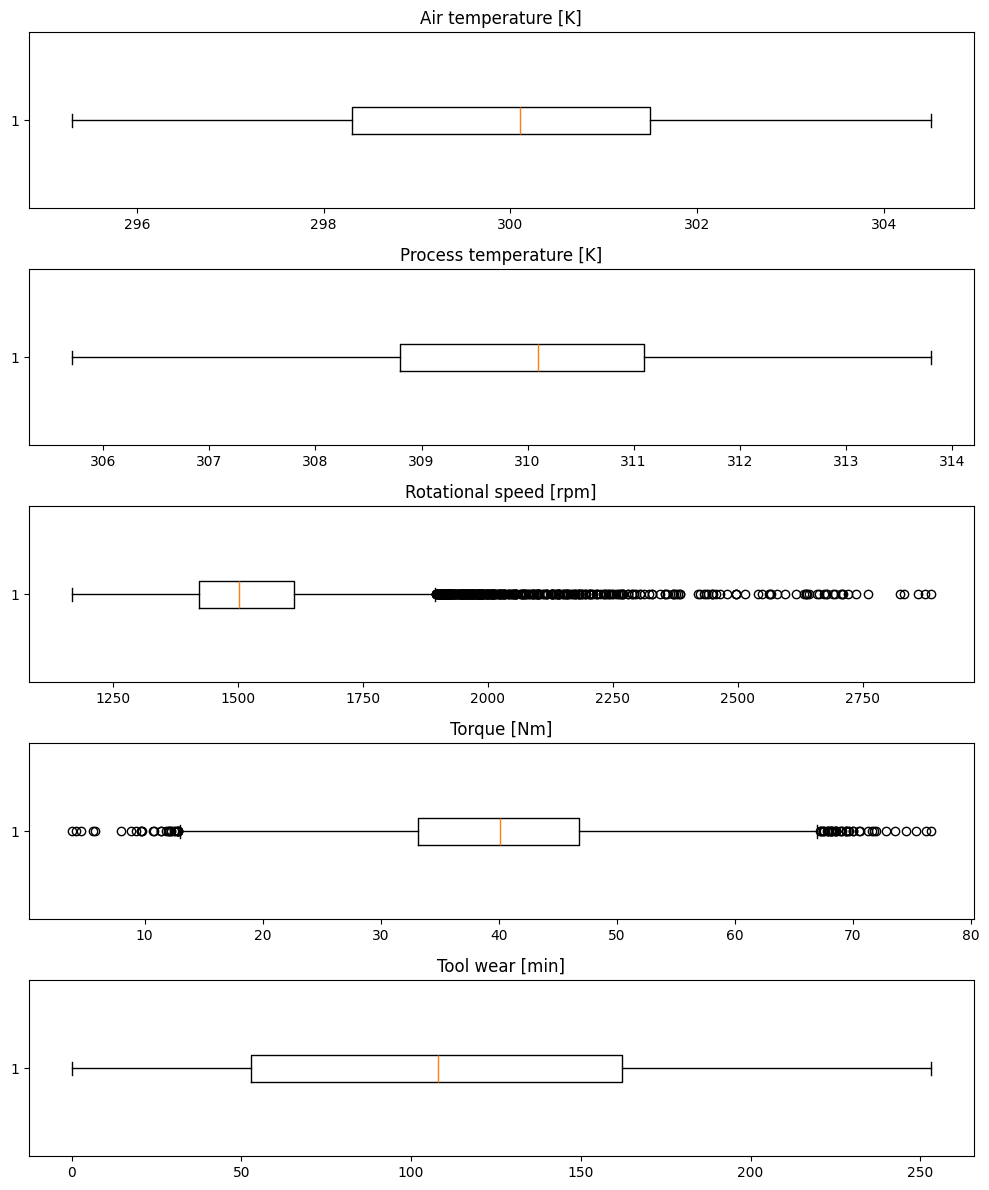

In [114]:
fig, axes = plt.subplots(
    len(measurement_features),
    1,
    figsize=(10, 12)
)

for ax, feature in zip(axes, measurement_features):
    ax.boxplot(df[feature], vert=False)
    ax.set_title(feature)

plt.tight_layout()
plt.show()

The distributions show that the machine measurements have substantially
different numerical ranges. For example, rotational speed is measured in
thousands of rpm, while torque is measured in tens of Nm and the temperature
variables are around 300 K.

Rotational speed and torque also contain observations relatively far from
their central ranges. These observations are candidates for further
investigation, but they should not automatically be classified as errors.
An unusual value may represent a valid but uncommon operating condition.

The differences in numerical scale are particularly important for
distance-based outlier detection and motivate standardizing the features
before applying LOF.

### Feature selection

In [115]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[features].copy()

X.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,298.1,308.6,1551,42.8,0
1,298.2,308.7,1408,46.3,3
2,298.1,308.5,1498,49.4,5
3,298.2,308.6,1433,39.5,7
4,298.2,308.7,1408,40.0,9


Five numerical operating-condition variables are selected for outlier
detection:

- Air temperature [K]
- Process temperature [K]
- Rotational speed [rpm]
- Torque [Nm]
- Tool wear [min]

UDI and Product ID are excluded because they are identifiers. Numerical
differences between identifiers do not represent meaningful differences in
machine operating conditions.

Type is excluded from the primary outlier representation because it is a
categorical variable and the distance-based methods used in this analysis
operate naturally on numerical measurements. Including an arbitrary numerical
encoding of Type could introduce artificial distances between its categories.

Machine failure, TWF, HDF, PWF, OSF and RNF are also excluded from the
features used to detect outliers. These variables describe failure outcomes.
Including them would partly define an observation as unusual based on the
outcome that we later want to use when interpreting the detected observations.

Instead, the failure variables are retained in the original dataframe and
used after outlier detection to investigate whether unusual operating
conditions coincide with machine failures.

## Feature scaling

In [116]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

X_scaled.describe().T

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,-9.322321e-16,1.00005,-2.352278,-0.852397,0.047531,0.747476,2.247357
Process temperature [K],10000.0,-1.693934e-15,1.00005,-2.901986,-0.812558,0.063653,0.737662,2.557486
Rotational speed [rpm],10000.0,-2.330580e-16,1.00005,-2.068196,-0.645801,-0.199560,0.408444,7.514840
Torque [Nm],10000.0,5.424994e-16,1.00005,-3.630149,-0.680840,0.011345,0.683466,3.672902
Tool wear [min],10000.0,1.051603e-16,1.00005,-1.695984,-0.863318,0.000770,0.849147,2.278819


The selected variables use different units and numerical ranges. For example,
rotational speed is measured in rpm while torque is measured in Nm.

Local Outlier Factor is based on distances between observations. Without
scaling, variables with larger numerical ranges could contribute more strongly
to these distances simply because of their units rather than because they are
more important.

Therefore, the five features are standardized using StandardScaler. For each
feature, the mean is subtracted and the result is divided by the standard
deviation. The transformed variables consequently have approximately zero mean
and unit variance.

The standardized data are used by the outlier detection algorithms, while the
original values are retained for interpretation because values such as rpm and
Nm are more meaningful than standardized values.

## Local Outlier Factor

Local Outlier Factor (LOF) is a density-based outlier detection method. Rather
than determining whether an observation is globally extreme, LOF compares the
local density around an observation with the local densities around its
neighbours.

An observation receives a high outlier score when its local density is
substantially lower than that of the surrounding observations. This means that
LOF can detect observations that are unusual relative to their local
neighbourhood.

An important parameter is `n_neighbors`, denoted here as k. A small k focuses
on a very local neighbourhood, while a larger k evaluates the observation in
relation to a broader region of the dataset.

To investigate the influence of neighbourhood size, k = 10, 20 and 50 are
compared.

In [117]:
k_values = [10, 20, 50]

lof_scores = {}

for k in k_values:
    lof = LocalOutlierFactor(n_neighbors=k)

    lof.fit_predict(X_scaled)

    # sklearn returns negative_outlier_factor_ where more negative
    # values represent stronger anomalies. Negating it makes larger
    # values easier to interpret as stronger outliers.
    lof_scores[k] = -lof.negative_outlier_factor_

lof_results = pd.DataFrame(
    lof_scores,
    index=df.index
)

lof_results.columns = [
    f"LOF_k{k}" for k in k_values
]

lof_results.head()

,LOF_k10,LOF_k20,LOF_k50
0,1.050628,1.068460,1.049981
1,1.007765,1.000167,0.993853
2,1.164105,1.106623,1.074927
3,1.059511,1.024361,1.017523
4,1.079037,1.046551,1.039587


Scikit-learn stores the LOF result as `negative_outlier_factor_`, where more
negative values indicate more unusual observations. The values are negated in
this notebook so that a larger score consistently means a stronger outlier.

The transformation does not change the ranking of the observations; it only
makes the scores easier to interpret.

In [118]:
top_n = 10

for k in k_values:
    column = f"LOF_k{k}"

    print(f"\nTop {top_n} outliers for k = {k}")

    display(
        lof_results
        .nlargest(top_n, column)[[column]]
        .join(df[features + ["Machine failure"]])
    )


Top 10 outliers for k = 10


,LOF_k10,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
7763,1.804986,300.4,311.6,1200,76.6,3,1
901,1.738200,295.6,306.1,1256,62.3,142,0
1201,1.702191,296.9,308.0,1658,41.0,74,0
924,1.700962,295.5,306.0,1800,27.6,208,0
880,1.694728,295.8,306.3,1235,76.2,89,1
994,1.674331,296.2,307.2,1168,63.4,172,0
903,1.647705,295.7,306.2,2270,14.6,149,1
5115,1.603803,304.2,313.7,2113,18.4,139,0
420,1.595853,297.3,308.3,1301,39.6,5,0
1016,1.585697,296.3,307.2,1319,68.3,24,1



Top 10 outliers for k = 20


,LOF_k20,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
880,1.976655,295.8,306.3,1235,76.2,89,1
7763,1.826746,300.4,311.6,1200,76.6,3,1
924,1.731699,295.5,306.0,1800,27.6,208,0
994,1.675043,296.2,307.2,1168,63.4,172,0
9084,1.673418,297.2,307.9,1326,75.4,172,1
903,1.653623,295.7,306.2,2270,14.6,149,1
847,1.568642,296.4,307.4,2833,5.6,213,1
420,1.563220,297.3,308.3,1301,39.6,5,0
6333,1.555412,300.4,309.9,1415,31.8,192,0
1016,1.553550,296.3,307.2,1319,68.3,24,1



Top 10 outliers for k = 50


,LOF_k50,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
880,2.196613,295.8,306.3,1235,76.2,89,1
924,1.807633,295.5,306.0,1800,27.6,208,0
9084,1.800457,297.2,307.9,1326,75.4,172,1
7763,1.779535,300.4,311.6,1200,76.6,3,1
847,1.751188,296.4,307.4,2833,5.6,213,1
928,1.745258,295.6,306.0,1949,21.9,5,0
994,1.650765,296.2,307.2,1168,63.4,172,0
5394,1.649438,302.8,312.3,1262,70.5,234,1
1324,1.644199,298.8,310.1,1243,74.5,194,1
5127,1.626980,304.3,313.5,2245,15.1,172,0


In [119]:
top_n = 20

top_sets = {}

for k in k_values:
    column = f"LOF_k{k}"

    top_sets[k] = set(
        lof_results.nlargest(top_n, column).index
    )

for i in range(len(k_values)):
    for j in range(i + 1, len(k_values)):

        k1 = k_values[i]
        k2 = k_values[j]

        overlap = len(top_sets[k1] & top_sets[k2])

        print(
            f"k={k1} vs k={k2}: "
            f"{overlap}/{top_n} common observations"
        )

k=10 vs k=20: 12/20 common observations
k=10 vs k=50: 9/20 common observations
k=20 vs k=50: 14/20 common observations


In [120]:
for i in range(len(k_values)):
    for j in range(i + 1, len(k_values)):

        k1 = k_values[i]
        k2 = k_values[j]

        correlation, _ = spearmanr(
            lof_results[f"LOF_k{k1}"],
            lof_results[f"LOF_k{k2}"]
        )

        print(
            f"k={k1} vs k={k2}: "
            f"Spearman correlation = {correlation:.3f}"
        )

k=10 vs k=20: Spearman correlation = 0.827
k=10 vs k=50: Spearman correlation = 0.648
k=20 vs k=50: Spearman correlation = 0.853


### Influence of neighbourhood size

The results show that the choice of neighbourhood size affects the LOF results, although several strong outliers remain stable across different values of k.

For the 20 highest-ranked outliers, k=10 and k=20 share 12 observations, while k=20 and k=50 share 14. In comparison, k=10 and k=50 share only 9. This suggests that changing the  neighbourhood from 10 to 50 has a more substantial effect on which observations are considered the strongest outliers.

The Spearman rank correlations support this result. The rankings for k=10 and k=20 have a correlation of 0.827, while k=20 and k=50 have the highest correlation at 0.853. The correlation between k=10 and k=50 is lower at 0.648. Therefore, the two more similar neighbourhood sizes generally rank observations more consistently, while the largest change in neighbourhood size also produces the largest change in the ranking.

Some observations are nevertheless consistently identified as strong outliers. For example, observations 880, 7763, 924 and 994 appear among the ten strongest outliers for all three neighbourhood sizes. This indicates that their unusualness is not caused only by one particular choice of k.

Other observations are more sensitive to neighbourhood size. Observation 901, for example, is the second strongest outlier for k=10 but does not appear among the ten strongest for k=20 or k=50. In contrast, observation 9084 is not among the top ten for k=10, but becomes the fifth strongest for k=20 and the third strongest for k=50. This illustrates the local nature of LOF: changing k changes the region against which an observation's local density is compared.

For the remainder of the LOF analysis, k=20 is used as a reasonable intermediate neighbourhood size. It avoids focusing as narrowly on very local structure as k=10 while also avoiding the broader neighbourhood used by k=50. The relatively high rank correlations between k=20 and both alternative settings also suggest that it provides a useful compromise.
However, this does not establish k=20 as an objectively optimal value; the parameter experiment shows that the definition of an outlier depends to some extent on neighbourhood size.

Spearman rank correlation is used because the main interest is whether the
different neighbourhood sizes rank observations similarly rather than whether
their raw LOF scores are numerically identical.

A correlation close to 1 indicates that observations receive similar relative
outlier rankings under the two parameter settings.

In [121]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"],
    index=df.index
)

print(
    "Variance represented by two PCs:",
    pca.explained_variance_ratio_.sum()
)

Variance represented by two PCs: 0.7503185814369004


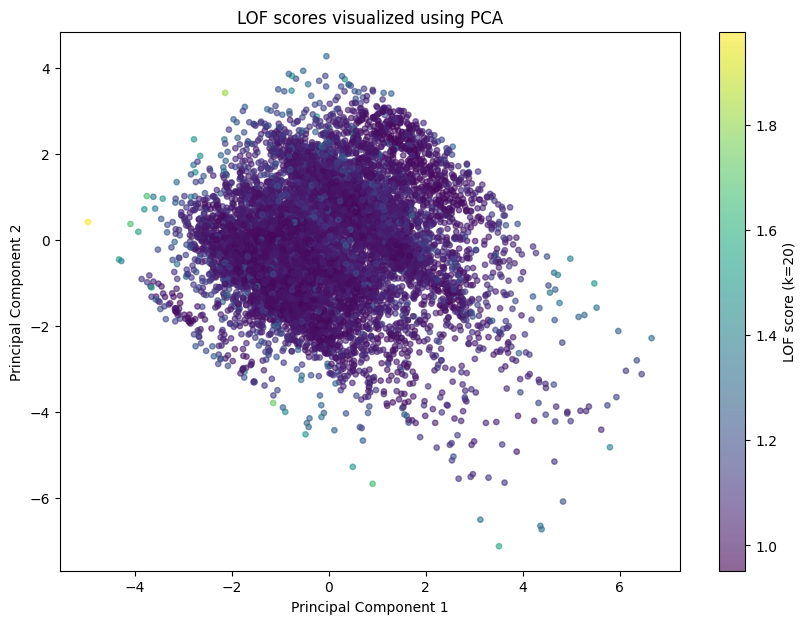

In [122]:
plt.figure(figsize=(10, 7))

scores = lof_results["LOF_k20"]

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=scores,
    s=15,
    alpha=0.6
)

plt.colorbar(scatter, label="LOF score (k=20)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("LOF scores visualized using PCA")

plt.show()

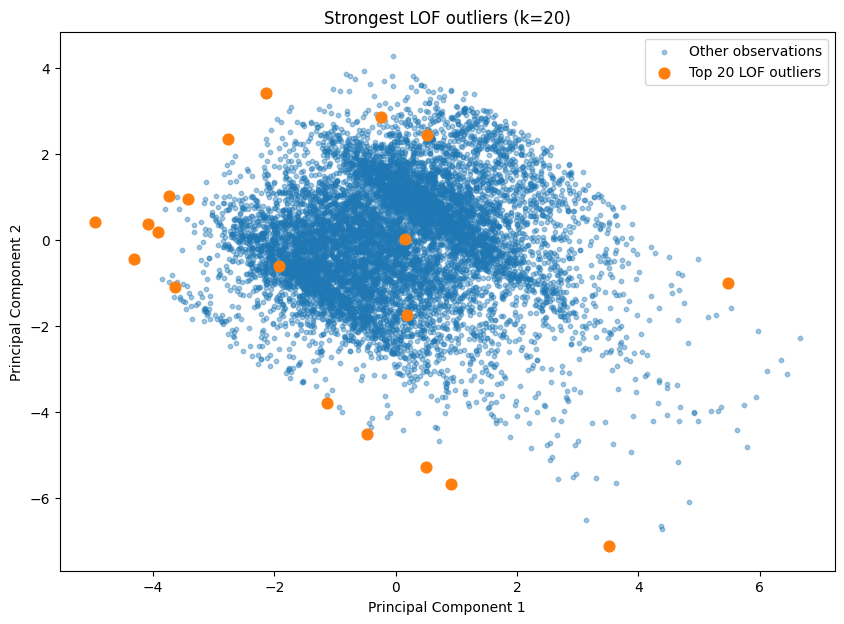

In [123]:
top_indices = lof_results.nlargest(
    20,
    "LOF_k20"
).index

plt.figure(figsize=(10, 7))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    s=10,
    alpha=0.4,
    label="Other observations"
)

plt.scatter(
    pca_df.loc[top_indices, "PC1"],
    pca_df.loc[top_indices, "PC2"],
    s=60,
    label="Top 20 LOF outliers"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Strongest LOF outliers (k=20)")
plt.legend()

plt.show()

PCA is used here only to visualize the five-dimensional feature space. LOF was calculated using all five standardized features rather than the two principal components.

Consequently, observations that do not appear visually isolated in the two-dimensional figure may still be unusual in the original five-dimensional space. The PCA visualization should therefore support the interpretation of LOF rather than be treated as evidence by itself.

In [124]:
top_indices = lof_results.nlargest(
    10,
    "LOF_k20"
).index

outlier_details = df.loc[
    top_indices,
    [
        "UDI",
        "Product ID",
        "Type",
        *features,
        "Machine failure",
        "TWF",
        "HDF",
        "PWF",
        "OSF",
        "RNF"
    ]
].copy()

outlier_details["LOF score"] = (
    lof_results.loc[top_indices, "LOF_k20"]
)

outlier_details

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,LOF score
880,881,M15740,M,295.8,306.3,1235,76.2,89,1,0,0,1,0,0,1.976655
7763,7764,L54943,L,300.4,311.6,1200,76.6,3,1,0,0,1,0,0,1.826746
924,925,L48104,L,295.5,306.0,1800,27.6,208,0,0,0,0,0,0,1.731699
994,995,M15854,M,296.2,307.2,1168,63.4,172,0,0,0,0,0,0,1.675043
9084,9085,L56264,L,297.2,307.9,1326,75.4,172,1,0,0,1,1,0,1.673418
903,904,L48083,L,295.7,306.2,2270,14.6,149,1,0,0,1,0,0,1.653623
847,848,L48027,L,296.4,307.4,2833,5.6,213,1,0,0,1,0,0,1.568642
420,421,M15280,M,297.3,308.3,1301,39.6,5,0,0,0,0,0,0,1.563220
6333,6334,M21193,M,300.4,309.9,1415,31.8,192,0,0,0,0,0,0,1.555412
1016,1017,M15876,M,296.3,307.2,1319,68.3,24,1,0,0,1,0,0,1.553550


### Interpretation of the LOF visualization

The first two principal components together represent approximately 75.0% of the variance in the five standardized features. The two-dimensional projection therefore retains a substantial amount of the variation in the dataset, although approximately 25% is not represented in the figure.

The highlighted observations show that many of the strongest LOF outliers occupy relatively unusual regions of the projection. However, not every high-LOF observation is necessarily visually separated from the main group. This is expected because LOF was calculated in the full five-dimensional feature space, whereas the figure shows only two dimensions.

The visualization therefore supports the presence of unusual observations, but the original feature values must be examined to understand why LOF assigned them high scores.

In [125]:
feature_z_scores = X_scaled.loc[top_indices].copy()

feature_z_scores["LOF score"] = (
    lof_results.loc[top_indices, "LOF_k20"]
)

feature_z_scores

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],LOF score
880,-2.102298,-2.497580,-1.694469,3.632776,-0.297733,1.976655
7763,0.197519,1.074667,-1.889699,3.672902,-1.648852,1.826746
924,-2.252286,-2.699783,1.457112,-1.242613,1.571838,1.731699
994,-1.902314,-1.890972,-2.068196,2.348723,1.006253,1.675043
9084,-1.402354,-1.419166,-1.186869,3.552522,1.006253,1.673418
903,-2.152294,-2.564981,4.078780,-2.546730,0.644908,1.653623
847,-1.802322,-1.756171,7.219205,-3.449580,1.650391,1.568642
420,-1.352358,-1.149563,-1.326319,-0.038814,-1.617430,1.563220
6333,0.197519,-0.071148,-0.690425,-0.821283,1.320467,1.555412
1016,-1.852318,-1.890972,-1.225915,2.840274,-1.318927,1.553550


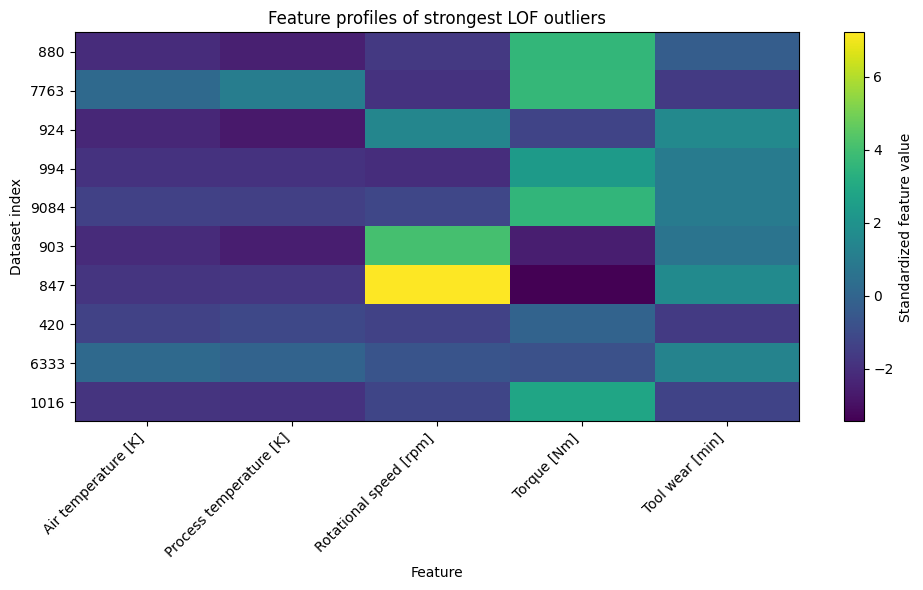

In [126]:
plt.figure(figsize=(10, 6))

plt.imshow(
    feature_z_scores[features],
    aspect="auto"
)

plt.colorbar(label="Standardized feature value")

plt.xticks(
    range(len(features)),
    features,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(top_indices)),
    top_indices
)

plt.xlabel("Feature")
plt.ylabel("Dataset index")
plt.title("Feature profiles of strongest LOF outliers")

plt.tight_layout()
plt.show()

### Investigation of the strongest LOF outliers

Examining the original and standardized feature values helps explain why these observations receive high LOF scores.

Observation 880 receives the highest LOF score for k=20 (1.977). Its torque is 76.2 Nm, approximately 3.63 standard deviations above the dataset mean, while its rotational speed is relatively low at 1235 rpm. Its air and process temperatures are also approximately 2.10 and 2.50 standard deviations below their respective means. It therefore represents an unusual combination of high torque, low rotational speed and relatively low temperatures. The observation is also recorded as a machine failure, specifically a power failure (PWF).

Observation 7763 shows a similar operating pattern. Its torque of 76.6 Nm is approximately 3.67 standard deviations above the mean and its rotational speed of 1200 rpm is approximately 1.89 standard deviations below the mean. Its tool wear is also very low at only 3 minutes. This combination places the observation in a relatively sparse part of the feature space. It is also recorded as a power failure.

A different type of anomaly can be seen for observations 903 and 847. Observation 903 has a rotational speed of 2270 rpm, approximately 4.08 standard deviations above the mean, together with unusually low torque. Observation 847 is even more extreme, with a rotational speed of 2833 rpm, approximately 7.22 standard deviations above the mean, and torque of only 5.6 Nm, approximately 3.45 standard deviations below the mean. Both are recorded as power failures.

The results therefore show that LOF is not identifying only one kind of extreme observation. Some strong outliers combine low rotational speed with very high torque, while others combine extremely high rotational speed with very low torque. These unusual combinations make the observations locally different from surrounding operating conditions.

### Strong outliers without machine failure

Not all strong LOF outliers correspond to machine failures. For example, observation 924 has the third-highest LOF score for k=20 but is not labelled as a machine failure. It combines relatively low temperatures with a high rotational speed of 1800 rpm and high tool wear of 208 minutes.

Observation 994 is another strong outlier without a recorded failure and combines very low rotational speed with high torque and relatively high tool wear.

These cases are important because an outlier should not automatically be interpreted as a data error or machine failure. The values remain plausible machine measurements and there is no evidence in the dataset that they are incorrect. They are therefore better interpreted as rare operating conditions unless additional information establishes that they are measurement errors.

In [127]:
top_n_values = [20, 50, 100]

for n in top_n_values:

    indices = lof_results.nlargest(
        n,
        "LOF_k20"
    ).index

    failures = df.loc[
        indices,
        "Machine failure"
    ].sum()

    print(
        f"Top {n} LOF outliers: "
        f"{failures} machine failures "
        f"({failures/n:.1%})"
    )

Top 20 LOF outliers: 11 machine failures (55.0%)
Top 50 LOF outliers: 22 machine failures (44.0%)
Top 100 LOF outliers: 41 machine failures (41.0%)


In [128]:
failure_rate = df["Machine failure"].mean()

print(
    f"Overall machine failure rate: "
    f"{failure_rate:.2%}"
)

Overall machine failure rate: 3.39%


### Relationship between LOF outliers and machine failure

Machine failures are strongly concentrated among the observations receiving the highest LOF scores. While only 3.39% of all observations in the dataset are labelled as machine failures, 55% of the top 20 LOF outliers are failures. The proportion is 44% among the top 50 and 41% among the top 100.

This provides evidence that unusual combinations of the selected operating measurements are associated with machine failure in this dataset. Importantly, the Machine failure variable was not included when calculating LOF, so this relationship was not directly built into the anomaly score.

However, Machine failure should not be treated as perfect ground truth for outlier detection. A machine can operate under an unusual combination of conditions without failing, and a failure does not necessarily have to occur in a sparse region of the five-dimensional feature space. The non-failure observations among the strongest LOF outliers demonstrate this distinction.

In [129]:
# Investigate machine failures that LOF does not rank as strong outliers

failure_indices = df.index[df["Machine failure"] == 1]

failure_lof = pd.DataFrame({
    "LOF score": lof_results.loc[failure_indices, "LOF_k20"]
})

failure_lof["LOF rank"] = (
    lof_results["LOF_k20"]
    .rank(ascending=False, method="min")
    .loc[failure_indices]
    .astype(int)
)

failure_lof = failure_lof.join(
    df.loc[failure_indices, features + [
        "TWF", "HDF", "PWF", "OSF", "RNF"
    ]]
)

failure_lof.sort_values("LOF rank", ascending=False).head(10)

,LOF score,LOF rank,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF
4044,0.969643,9894,301.9,310.9,1419,47.7,20,0,0,0,0,0
1437,0.970860,9862,298.8,309.9,1439,45.2,40,0,0,0,0,0
3787,0.988113,8596,302.3,310.8,1377,47.3,22,0,1,0,0,0
6340,0.989553,8423,300.5,309.9,1397,45.9,210,1,0,0,0,0
4851,0.990770,8237,303.7,312.1,1363,51.8,90,0,1,0,0,0
3611,0.991437,8155,301.7,310.9,1405,46.4,207,1,0,0,0,1
3760,0.991542,8141,302.3,310.9,1377,46.8,166,0,1,0,0,0
9015,0.991551,8140,297.2,308.1,1431,49.7,210,0,0,0,0,0
3829,0.991975,8084,302.3,310.9,1366,48.4,130,0,1,0,0,0
4096,0.992131,8063,301.9,310.4,1370,51.7,153,0,1,0,0,0


### Machine failures not identified as strong LOF outliers

There are also machine failures that LOF does not identify as strong outliers. For example, observation 4044 is labelled as a machine failure but has an LOF score of approximately 0.970 and is ranked 9894 out of 10,000 observations. Observation 1437 shows a similar result, with an LOF score of approximately 0.971 and a rank of 9862.

Several other failure observations also receive relatively normal LOF scores. For example, observations 3787, 4851 and 3829 are heat-dissipation failures (HDF), but their LOF scores are close to 1.

This shows that machine failure and statistical unusualness are not equivalent. LOF identifies observations whose local density differs from their neighbours. If a machine fails while its selected operating measurements remain similar to nearby observations, LOF may not identify it as an outlier.

Therefore, the failure labels should not be treated as perfect ground truth for the outlier detection task. Some failures are associated with unusual operating conditions, while others occur in regions that LOF considers relatively normal.

## Isolation Forest

Isolation Forest detects anomalies using random decision trees. The central
idea is that unusual observations should be easier to isolate from the rest of
the dataset and therefore require fewer random splits.

This differs from LOF. LOF measures how the local density around an observation
compares with the density around its neighbours, while Isolation Forest
attempts to isolate observations through random partitioning.

Comparing the two methods is therefore useful because they represent different
definitions of what makes an observation unusual.

In [130]:
isolation_forest = IsolationForest(
    n_estimators=300,
    contamination="auto",
    random_state=42
)

isolation_forest.fit(X_scaled)

isolation_scores = -isolation_forest.score_samples(X_scaled)

## k-Nearest-Neighbour Distance

As a third approach, a k-nearest-neighbour distance score is used.

For each observation, the distance to its kth nearest neighbour is calculated.
An observation whose kth nearest neighbour is far away lies in a relatively
sparse region of the feature space and therefore receives a high outlier
score.

This method provides a simple and interpretable distance-based baseline. It is
particularly useful when comparing the results with LOF because both use
neighbourhood information but evaluate unusualness differently. LOF compares
local densities, whereas the kNN score directly measures neighbour distance.

In [131]:
k = 10

knn = NearestNeighbors(
    n_neighbors=k + 1
)

knn.fit(X_scaled)

distances, indices = knn.kneighbors(X_scaled)

# First neighbour is the observation itself.
knn_scores = distances[:, -1]

In [132]:
results = pd.DataFrame(
    {
        "LOF": lof_results["LOF_k20"],
        "Isolation Forest": isolation_scores,
        "kNN Distance": knn_scores
    },
    index=df.index
)

results.head()

,LOF,Isolation Forest,kNN Distance
0,1.068460,0.487771,0.467951
1,1.000167,0.480407,0.388251
2,1.106623,0.488467,0.510444
3,1.024361,0.466544,0.431229
4,1.046551,0.469220,0.438856


In [133]:
top_n = 20

method_top = {}

for method in results.columns:

    method_top[method] = set(
        results.nlargest(top_n, method).index
    )

    print(f"\nTop {top_n}: {method}")

    display(
        results
        .nlargest(top_n, method)[[method]]
        .join(df[features + ["Machine failure"]])
        .head(10)
    )


Top 20: LOF


,LOF,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
880,1.976655,295.8,306.3,1235,76.2,89,1
7763,1.826746,300.4,311.6,1200,76.6,3,1
924,1.731699,295.5,306.0,1800,27.6,208,0
994,1.675043,296.2,307.2,1168,63.4,172,0
9084,1.673418,297.2,307.9,1326,75.4,172,1
903,1.653623,295.7,306.2,2270,14.6,149,1
847,1.568642,296.4,307.4,2833,5.6,213,1
420,1.563220,297.3,308.3,1301,39.6,5,0
6333,1.555412,300.4,309.9,1415,31.8,192,0
1016,1.553550,296.3,307.2,1319,68.3,24,1



Top 20: Isolation Forest


,Isolation Forest,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
5152,0.706839,304.3,313.5,2643,12.7,21,0
847,0.698675,296.4,307.4,2833,5.6,213,1
903,0.698248,295.7,306.2,2270,14.6,149,1
1095,0.691946,296.9,307.5,2721,9.3,18,1
4988,0.688476,303.8,313.1,2497,13.0,5,1
887,0.686041,295.7,306.2,2161,16.5,105,0
4997,0.684874,303.6,312.8,2659,11.4,26,1
928,0.682930,295.6,306.0,1949,21.9,5,0
880,0.681993,295.8,306.3,1235,76.2,89,1
5127,0.679174,304.3,313.5,2245,15.1,172,0



Top 20: kNN Distance


,kNN Distance,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
847,2.638481,296.4,307.4,2833,5.6,213,1
5152,2.420076,304.3,313.5,2643,12.7,21,0
4296,2.357154,301.8,310.2,2825,5.8,215,1
1784,2.339870,298.3,308.0,2886,3.8,57,1
1095,2.163573,296.9,307.5,2721,9.3,18,1
463,2.065344,297.4,308.7,2874,4.2,118,1
50,2.065207,298.9,309.1,2861,4.6,143,1
4997,2.040559,303.6,312.8,2659,11.4,26,1
4988,1.947947,303.8,313.1,2497,13.0,5,1
903,1.931264,295.7,306.2,2270,14.6,149,1


In [134]:
results.corr(method="spearman")

,LOF,Isolation Forest,kNN Distance
LOF,1.000000,0.445799,0.789445
Isolation Forest,0.445799,1.000000,0.709121
kNN Distance,0.789445,0.709121,1.000000


Spearman correlations are calculated between the anomaly scores to determine
how similarly the methods rank the observations.

A high correlation indicates that two methods generally agree about which
observations are more unusual, whereas a lower correlation indicates that the
methods capture different forms of anomalous behaviour.

In [135]:
for method1 in results.columns:
    for method2 in results.columns:

        if method1 < method2:

            overlap = len(
                method_top[method1] &
                method_top[method2]
            )

            print(
                method1,
                "vs",
                method2,
                ":",
                overlap,
                f"of top {top_n}"
            )

LOF vs kNN Distance : 4 of top 20
Isolation Forest vs LOF : 7 of top 20
Isolation Forest vs kNN Distance : 11 of top 20


In [136]:
common_all = (
    method_top["LOF"]
    & method_top["Isolation Forest"]
    & method_top["kNN Distance"]
)

df.loc[
    list(common_all),
    features + [
        "Machine failure",
        "TWF",
        "HDF",
        "PWF",
        "OSF",
        "RNF"
    ]
]

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
903,295.7,306.2,2270,14.6,149,1,0,0,1,0,0
880,295.8,306.3,1235,76.2,89,1,0,0,1,0,0
847,296.4,307.4,2833,5.6,213,1,0,0,1,0,0
5127,304.3,313.5,2245,15.1,172,0,0,0,0,0,0


In [137]:
estimator_values = [50, 100, 300, 500]

isolation_parameter_scores = {}

for n in estimator_values:

    model = IsolationForest(
        n_estimators=n,
        contamination="auto",
        random_state=42
    )

    model.fit(X_scaled)

    isolation_parameter_scores[n] = (
        -model.score_samples(X_scaled)
    )

In [138]:
base_top = set(
    np.argsort(
        isolation_parameter_scores[300]
    )[-20:]
)

for n in estimator_values:

    current_top = set(
        np.argsort(
            isolation_parameter_scores[n]
        )[-20:]
    )

    overlap = len(base_top & current_top)

    print(
        f"{n} estimators: "
        f"{overlap}/20 overlap with 300 estimators"
    )

50 estimators: 17/20 overlap with 300 estimators
100 estimators: 17/20 overlap with 300 estimators
300 estimators: 20/20 overlap with 300 estimators
500 estimators: 18/20 overlap with 300 estimators


Increasing the number of trees does not fundamentally change the definition of an anomaly used by Isolation Forest. Instead, additional trees generally make the anomaly score more stable because the result is averaged across more random partitions.

The parameter experiment is therefore interpreted in terms of stability rather than selecting whichever setting produces the most desirable set of outliers.

The observed results support this interpretation. Using 50 and 100 trees produces 17 of the same top 20 outliers as the 300-tree model, while using 500 trees produces 18 of the same top 20. Therefore, the strongest detected outliers are relatively stable with respect to the number of trees, although small differences remain because Isolation Forest contains random partitioning.

In [139]:
for method in results.columns:

    indices = results.nlargest(
        100,
        method
    ).index

    failures = df.loc[
        indices,
        "Machine failure"
    ].sum()

    print(
        f"{method}: "
        f"{failures}/100 top outliers "
        f"are machine failures"
    )

LOF: 41/100 top outliers are machine failures
Isolation Forest: 33/100 top outliers are machine failures
kNN Distance: 46/100 top outliers are machine failures


## Final Evaluation and Conclusion

The three methods identify different but overlapping forms of unusual machine operation. Their results should not be evaluated only according to the Machine failure variable because machine failure is not a true ground-truth label for statistical outliers. Nevertheless, it provides useful external information for interpreting the detected observations.

Among the 100 highest-ranked observations, 41% of the LOF outliers, 33% of the Isolation Forest outliers and 46% of the kNN-distance outliers correspond to recorded machine failures. These proportions are substantially higher than the overall machine failure rate of 3.39%. This suggests that all three methods detect operating conditions that are associated with machine failure, although many detected outliers are valid observations without a recorded failure.

The methods also differ considerably in their rankings. LOF and kNN distance have the strongest rank correlation at approximately 0.789, while LOF and Isolation Forest have a considerably lower correlation of approximately 0.446. Only four observations occur among the top 20 outliers of all three methods. This demonstrates that the choice of method affects which type of unusual behaviour is emphasized.

For this dataset, I would choose LOF as the primary outlier detection technique. The purpose of the analysis is to identify unusual combinations of operating measurements rather than simply extreme individual values. LOF is useful for this because it compares the density around an observation with the density of its local neighbourhood. The analysis also showed that several of its strongest outliers could be explained through unusual combinations of rotational speed, torque, temperature and tool wear.

The LOF results were reasonably stable when changing the neighbourhood size, although the differences between k=10, k=20 and k=50 also demonstrate that the method is sensitive to the definition of the local neighbourhood. Using k=20 provided a useful intermediate setting rather than being established as an objectively optimal value.

The comparison with Isolation Forest and kNN distance is still valuable. Observations identified by several methods, such as 880, 903 and 847, provide particularly convincing examples of unusual operating conditions. At the same time, observations detected by only one method demonstrate that there is no single universal definition of an outlier. The final interpretation should therefore consider the anomaly scores together with the original machine measurements and the context of the observations.